# Práctica 4 - Anatomía de un dataset de Machine Learning
**Sesión 4 - El dataset**

## Objetivos
Analizar un dataset desde el punto de vista de Machine Learning: muestras, variables, identificadores, características, target, \(X\), \(y\), tipos conceptuales, valores ausentes y distribuciones.

> El objetivo principal no es escribir mucho código, sino **interpretar correctamente los datos**.

## Contexto
Una plataforma de comercio electrónico dispone de información histórica sobre sus clientes. Trabajaremos con `clientes_ecommerce.csv`.

| Variable | Descripción |
|---|---|
| `cliente_id` | Identificador único |
| `edad` | Edad |
| `antiguedad_meses` | Meses desde el registro |
| `ingresos_anuales` | Ingresos anuales estimados |
| `gasto_mensual` | Gasto medio mensual |
| `num_compras` | Compras del último año |
| `devoluciones` | Devoluciones del último año |
| `dispositivo` | Dispositivo principal |
| `zona` | Zona de residencia |
| `nivel_fidelidad` | Bronce, Plata, Oro o Platino |
| `satisfaccion` | Valoración de 1 a 5 |
| `compra_proximo_mes` | Compra el mes siguiente: Sí/No |

Completa las celdas `# TODO` y responde en Markdown.

## Preparación

In [1]:
# TODO: importa NumPy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en df
df = pd.read_csv('clientes_ecommerce.csv')

## Parte 1 - Comprender el dataset
### Ejercicio 1 - Primera inspección
Muestra las primeras 10 filas.

In [2]:
# TODO: muestra las primeras 10 filas
print(df.head(10))

   cliente_id  edad  antiguedad_meses  ingresos_anuales  gasto_mensual  \
0       20001    67             102.0           9000.00          60.73   
1       20002    28              93.0          35683.86         131.74   
2       20003    19              87.0          37152.19          55.33   
3       20004    55              79.0          40158.29          24.33   
4       20005    39               3.0          27317.06          88.78   
5       20006    45              25.0          32627.01          59.77   
6       20007    22             105.0          44101.68         109.67   
7       20008    39              90.0          44882.10          57.56   
8       20009    55              56.0          55299.19          49.94   
9       20010    38              93.0           9000.00         110.69   

   num_compras  devoluciones dispositivo    zona nivel_fidelidad  \
0            7             3       Móvil   Oeste             Oro   
1            6             1       Móvil    Este 

### Respuesta
1. ¿Qué representa una fila? 
2. ¿Qué representa una columna?
3. ¿Cuál es la unidad de observación?
4. ¿Todas las columnas son características? Justifica.

**Respuesta:** Escribe aquí.
1. Una fila representa un cliente individual con todos sus datos asociados (edad, ingresos, antigüedad, número de compras, satisfacción, etc.).
2. Una columna representa una característica o atributo de los clientes. Por ejemplo, edad indica la edad del cliente, ingresos_anuales sus ingresos y zona la región donde se encuentra.
3. La unidad de observación es cada cliente, ya que cada fila contiene información correspondiente a un cliente distinto identificado por cliente_id.
4. No todas son características; cliente_id es un identificador y compra_proximo_mes puede ser la variable objetivo.

### Ejercicio 2 - Dimensiones
Obtén `df.shape`.

In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

### Respuesta
- Número de muestras:    
- Número de columnas: 
- ¿Tenemos el mismo número de características? ¿Por qué? 

Escribe aquí.
- Número de muestras: 400
- Número de columnas: 12
- No tenemos 12 características porque algunas columnas no se usan como variables predictoras, como cliente_id (identificador) y la variable objetivo compra_proximo_mes.

## Parte 2 - Clasificación de variables
### Ejercicio 3 - Tipos almacenados

In [4]:
# TODO: consulta df.dtypes
df.dtypes

cliente_id              int64
edad                    int64
antiguedad_meses      float64
ingresos_anuales      float64
gasto_mensual         float64
num_compras             int64
devoluciones            int64
dispositivo               str
zona                      str
nivel_fidelidad           str
satisfaccion            int64
compra_proximo_mes        str
dtype: object

### Ficha de variables
Clasifica cada variable como: **Identificador, Numérica discreta, Numérica continua, Categórica nominal, Categórica ordinal o Target**.

| Variable | dtype | Tipo conceptual | ¿Feature candidata? |
|---|---|---|---|
| cliente_id | int64 |Identificador |No |
| edad |int64 |Númerica discreta |Sí |
| antiguedad_meses |float64 |Numérica continua |Sí |
| ingresos_anuales |float64 |Numérica continua |Sí |
| gasto_mensual |float64 |Numérica continua |Sí |
| num_compras |int64 |Numérica discreta |Sí |
| devoluciones |int64 |Numérica discreta |Sí |
| dispositivo |str |Categórica nominal |Sí |
| zona |str |Categórica nominal |Sí |
| nivel_fidelidad |str |Categórica ordinal |Sí |
| satisfaccion |int64 |Categórica ordinal |Sí |
| compra_proximo_mes |str |Target |No |

No clasifiques únicamente por `dtype`.

### Ejercicio 4 - `cliente_id`
Muestra sus primeros 10 valores.

In [5]:
# TODO: analiza cliente_id
df['cliente_id'].describe()

count      400.000000
mean     20200.500000
std        115.614301
min      20001.000000
25%      20100.750000
50%      20200.500000
75%      20300.250000
max      20400.000000
Name: cliente_id, dtype: float64

### Respuesta
1. ¿Qué dtype tiene?
2. ¿Es por ello cuantitativa?
3. ¿Tiene sentido calcular su media?
4. ¿La incluirías inicialmente en \(X\)?
5. Justifica.

Escribe aquí.
1. Tiene dtype int64 (aunque describe() lo muestra como float64 porque calcula estadísticas numéricas).
2. No. Aunque está almacenada como un número entero, conceptualmente es un identificador, no una variable cuantitativa que mida una característica del cliente.
3. No. La media (20200,5) no aporta ninguna información útil sobre los clientes, ya que los valores son simplemente códigos identificativos.
4. No.
5. Porque cliente_id es un identificador único para cada cliente. No describe ninguna característica relevante de su comportamiento o perfil y podría introducir ruido en el modelo. Por tanto, debe eliminarse de las variables predictoras (X).

### Ejercicio 5 - `satisfaccion`
Muestra la frecuencia de sus valores ordenados.

In [6]:
# TODO: value_counts() + sort_index()
df['cliente_id'].value_counts().sort_index()

cliente_id
20001    1
20002    1
20003    1
20004    1
20005    1
        ..
20396    1
20397    1
20398    1
20399    1
20400    1
Name: count, Length: 400, dtype: int64

Sabemos que 1 = Muy insatisfecho, 2 = Insatisfecho, 3 = Neutral, 4 = Satisfecho y 5 = Muy satisfecho.

### Respuesta
1. ¿Cómo la almacena pandas?
2. ¿Es simplemente numérica?
3. ¿Existe un orden?
4. ¿Nominal u ordinal?
5. Explica `dtype` frente a significado conceptual.

Escribe aquí.
1. Pandas la almacena como int64, es decir, como números enteros.
2. No. Aunque su dtype es numérico, su significado no es el de una magnitud numérica. Los valores 1, 2, 3, 4 y 5 representan categorías de satisfacción.
3. Sí. Hay un orden natural: 1 = Muy insatisfecho < 2 = Insatisfecho < 3 = Neutral < 4 = Satisfecho < 5 = Muy satisfecho.
4. Es una variable categórica ordinal, porque las categorías tienen un orden lógico.
5. El dtype indica cómo se almacenan los datos en memoria (en este caso, int64). El significado conceptual indica qué representan esos datos. Aunque pandas la almacena como números enteros, conceptualmente no es una variable numérica continua o discreta, sino una escala ordinal de satisfacción donde los números son etiquetas ordenadas.


## Parte 3 - Calidad de los datos
### Ejercicio 6 - Información estructural

In [7]:
# TODO: utiliza df.info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Respuesta
1. ¿Cuántas muestras hay?
2. ¿Qué tipos técnicos aparecen?
3. ¿Todas las columnas tienen los mismos valores no nulos?
4. ¿Qué columnas contienen ausentes?
5. ¿Cuántos faltan?

Escribe aquí.
1. Hay 400 muestras, ya que el DataFrame tiene 400 entradas (0 a 399).
2. Aparecen tres tipos de datos: int64, float64 y str.
3. No. Algunas columnas tienen menos de 400 valores no nulos.
4. Las columnas con valores ausentes son: antiguedad_meses (395 no nulos), ingresos_anuales (396 no nulos) y gasto_mensual (397 no nulos).
5. Como hay 400 filas:

- antiguedad_meses: 400 - 395 = 5 valores faltantes.

- ingresos_anuales: 400 - 396 = 4 valores faltantes.

- gasto_mensual: 400 - 397 = 3 valores faltantes.

### Ejercicio 7 - Valores ausentes
Calcula cantidad y porcentaje por columna.

In [8]:
# TODO: valores ausentes por columna
df.isnull().sum()

# TODO: porcentaje de ausentes por columna
df.isnull().sum() / len(df) * 100

cliente_id            0.00
edad                  0.00
antiguedad_meses      1.25
ingresos_anuales      1.00
gasto_mensual         0.75
num_compras           0.00
devoluciones          0.00
dispositivo           0.00
zona                  0.00
nivel_fidelidad       0.00
satisfaccion          0.00
compra_proximo_mes    0.00
dtype: float64

### Reflexión
¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000? ¿Por qué son útiles los porcentajes?

Escribe aquí.

**¿Es lo mismo que falten 5 valores entre 50 muestras que entre 100.000?**

No. Porque la importancia de los valores faltantes depende del porcentaje que representan sobre el total de muestras.

- 5 valores faltantes de 50 muestras = 10% de ausencias.

- 5 valores faltantes de 100.000 muestras = 0,005% de ausencias.

Aunque faltan 5 datos en ambos casos, el impacto es mucho mayor cuando el conjunto de datos es pequeño.

**¿Por qué son útiles los porcentajes?**

Porque permiten comparar correctamente la cantidad de valores ausentes entre datasets de tamaños diferentes y evaluar mejor la gravedad del problema. Un porcentaje indica el peso real de los datos faltantes respecto al total de observaciones.

## Parte 4 - Construcción de X e y
Queremos predecir: **¿realizará el cliente una compra el próximo mes?**

### Ejercicio 8 - Variable objetivo

In [11]:
# TODO: crea y
y = df['compra_proximo_mes']

# TODO: muestra y.head() y y.shape
print(y.head())
print(y.shape)

0    No
1    No
2    Sí
3    Sí
4    No
Name: compra_proximo_mes, dtype: str
(400,)


### Respuesta
1. ¿Qué representa cada elemento de \(y\)?
2. ¿Cuántos contiene?
3. ¿Por qué el target no debe incluirse también en \(X\)?

Escribe aquí.
1. Cada elemento representa si un cliente realizará una compra el próximo mes, tomando valores como "Sí" o "No".
2. Contiene 400 elementos, uno por cada cliente del dataset (y.shape = (400,)).
3. Porque compra_proximo_mes es la variable que queremos predecir. Si se incluyera también en X, el modelo tendría acceso a la respuesta correcta durante el entrenamiento, produciendo data leakage (fuga de información) y resultados irreales.

### Ejercicio 9 - Construir \(X\)
Usa: `edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad`, `satisfaccion`.

No incluyas `cliente_id` ni `compra_proximo_mes`.

In [10]:
# TODO: crea X
x = df.drop(columns=['cliente_id', 'compra_proximo_mes'])

# TODO: muestra X.head() y X.shape
print(x.head())
print(x.shape)

   edad  antiguedad_meses  ingresos_anuales  gasto_mensual  num_compras  \
0    67             102.0           9000.00          60.73            7   
1    28              93.0          35683.86         131.74            6   
2    19              87.0          37152.19          55.33            8   
3    55              79.0          40158.29          24.33            7   
4    39               3.0          27317.06          88.78            5   

   devoluciones dispositivo   zona nivel_fidelidad  satisfaccion  
0             3       Móvil  Oeste             Oro             5  
1             1       Móvil   Este          Bronce             2  
2             1   Ordenador   Este           Plata             5  
3             0   Ordenador  Norte          Bronce             4  
4             0       Móvil    Sur          Bronce             4  
(400, 10)


### Ejercicio 10 - Dimensiones
Completa y explica:

- \(n =\) n = 400 → número de muestras (filas).
- \(p =\) p = 10 → número de características o variables predictoras (columnas de X).
- \(X.shape =\) X.shape = (400, 10) → 400 observaciones y 10 features.
- \(y.shape =\) y.shape = (400, ) → 400 valores de la variable objetivo, uno por cada muestra.

## Parte 5 - ¿Está etiquetado?
### Ejercicio 11
1. ¿Tenemos \(X\)?
2. ¿Tenemos \(y\)?
3. ¿Está etiquetado?
4. ¿Puede usarse para aprendizaje supervisado?
5. ¿Qué tipo de problema es predecir `compra_proximo_mes`?
6. ¿Binario o multiclase?
7. ¿Cuáles son las clases?

**Respuesta:** Escribe aquí.
1. Sí. Tenemos la matriz X con las variables predictoras: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones, dispositivo, zona, nivel_fidelidad y satisfaccion.
2. Sí. Tenemos la variable objetivo y = compra_proximo_mes.
3. Sí. Cada cliente tiene asociada una etiqueta ("Sí" o "No") que indica si realizará una compra el próximo mes.
4. Sí. Al disponer de variables predictoras (X) y de una variable objetivo (y), el conjunto de datos puede utilizarse para aprendizaje supervisado.
5. Es un problema de clasificación.
6. Es un problema de clasificación binaria, porque solo existen dos posibles resultados.
7. Las clases son:

- Sí (comprará el próximo mes)

- No (no comprará el próximo mes)


## Parte 6 - Distribuciones
### Ejercicio 12 - Variables categóricas
Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes` con frecuencias absolutas y relativas.

In [18]:
# TODO: value_counts() y value_counts(normalize=True) para las cuatro variables
# dispositivo
print(df['dispositivo'].value_counts())
print(df['dispositivo'].value_counts(normalize=True))

# zona
print(df['zona'].value_counts())
print(df['zona'].value_counts(normalize=True))

# nivel_fidelidad
print(df['nivel_fidelidad'].value_counts())
print(df['nivel_fidelidad'].value_counts(normalize=True))

# compra_proximo_mes
print(df['compra_proximo_mes'].value_counts())
print(df['compra_proximo_mes'].value_counts(normalize=True))



dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64
compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64


### Tabla resumen
| Variable | Categoría más frecuente | Frecuencia | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60,50% |
| zona | Este | 89 | 22,25% |
| nivel_fidelidad | Bronce | 162 | 40,50% |
| compra_proximo_mes | No | 246 | 61,50% |

### Ejercicio 13 - Visualización del target
Crea un gráfico de barras con título y etiquetas.

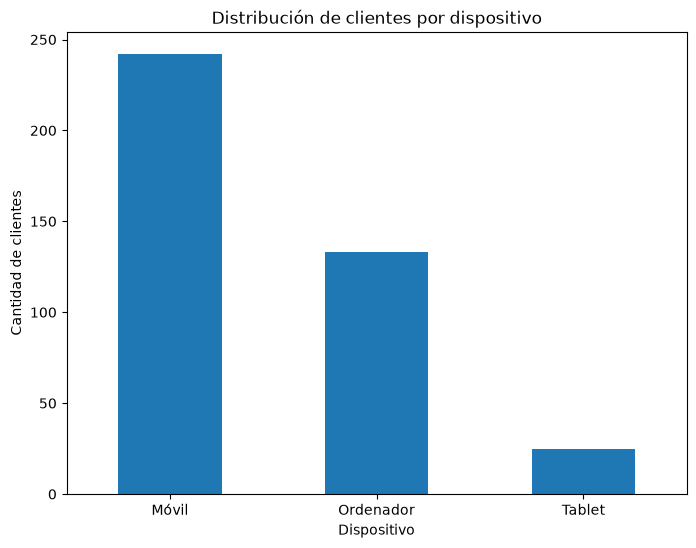

In [22]:
# TODO: gráfico de barras
plt.figure(figsize=(8, 6))
df['dispositivo'].value_counts().plot(kind='bar')
plt.xlabel('Dispositivo')
plt.ylabel('Cantidad de clientes')
plt.title('Distribución de clientes por dispositivo')
plt.xticks(rotation=0)
plt.show()

### Interpretación
¿Las clases aparecen aproximadamente con la misma frecuencia? Justifica con datos.

No, las clases no aparecen aproximadamente con la misma frecuencia.

Según los datos:

- Móvil: 242 clientes (60,5%)

- Ordenador: 133 clientes (33,25%)

- Tablet: 25 clientes (6,25%)

Se observa un claro predominio de los clientes que utilizan Móvil, que representan más de la mitad del total. En cambio, Tablet es una categoría muy minoritaria, con solo el 6,25% de los clientes.

Conclusión: La distribución de la variable dispositivo está desbalanceada, ya que las frecuencias de las categorías son muy diferentes entre sí.

## Parte 7 - Variables numéricas
### Ejercicio 14 - Estadística descriptiva
Analiza `edad`, `ingresos_anuales`, `gasto_mensual`, `num_compras` y `devoluciones`.

In [25]:
# TODO: describe() solo sobre las columnas indicadas
df[['edad', 'ingresos_anuales', 'gasto_mensual', 'num_compras', 'devoluciones']].describe()

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.000000,396.000000,397.000000,400.000000,400.000000
mean,46.402500,36440.920379,69.089320,8.225000,1.225000
std,18.007809,14325.228166,39.023238,2.780955,1.136929
min,18.000000,9000.000000,5.770000,2.000000,0.000000
25%,33.000000,26034.092500,39.720000,6.000000,0.000000
50%,45.000000,36817.275000,61.170000,8.000000,1.000000
75%,59.000000,45969.032500,90.150000,10.000000,2.000000
max,195.000000,82925.370000,260.000000,17.000000,5.000000


### Interpretación
Escribe una conclusión breve para cada variable:
- **edad:** media de 46,4 años; posible valor atípico en 195 años.
- **ingresos_anuales:** media de 36.441 €; dispersión moderada y máximos elevados.
- **gasto_mensual:** media de 69,09 €; algunos clientes gastan mucho más que la mayoría.
- **num_compras:** media de 8,23 compras; la mayoría realiza entre 6 y 10.
- **devoluciones:** media de 1,23 devoluciones; generalmente son pocas.

### Ejercicio 15 - Detectar algo sospechoso
1. ¿Hay algún valor poco razonable?
2. ¿En qué variable?
3. ¿Por qué es sospechoso? 
4. ¿Lo eliminarías inmediatamente? 
5. ¿Qué comprobarías antes?

**Respuesta:** Escribe aquí.
1. Sí.
2. En la variable 'edad'.
3. Porque en la estadística descriptiva aparece una edad máxima de 195 años, un valor que no es realista para una persona. Es muy probable que se trate de un error de introducción de datos, de medición o de procesamiento.
4. No. Antes de eliminarlo conviene investigar su origen para confirmar que realmente es un error.
5. 
- Revisar el registro original de ese cliente.
- Comprobar si se ha producido un error al cargar o transformar los datos.
- Verificar si hay más edades anómalas o fuera de rango.
- Analizar cuántos casos afectados existen.
- Decidir después si corregir el valor, imputarlo o eliminar el registro.

## Parte 8 - Distribuciones numéricas
### Ejercicio 16
Crea histogramas independientes de `edad`, `ingresos_anuales`, `gasto_mensual` y `num_compras`.

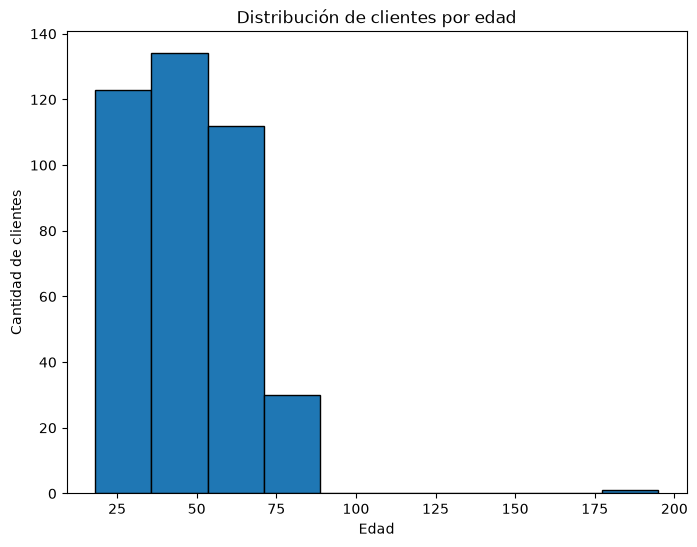

In [26]:
# TODO: histograma de edad
plt.figure(figsize=(8, 6))
plt.hist(df['edad'], bins=10, edgecolor='black')
plt.xlabel('Edad')
plt.ylabel('Cantidad de clientes')
plt.title('Distribución de clientes por edad')
plt.show()

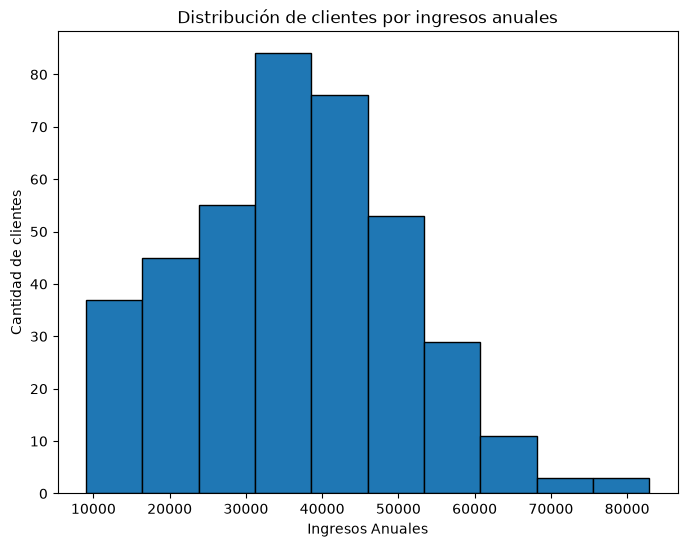

In [27]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8, 6))
plt.hist(df['ingresos_anuales'], bins=10, edgecolor='black')
plt.xlabel('Ingresos Anuales')
plt.ylabel('Cantidad de clientes')
plt.title('Distribución de clientes por ingresos anuales')
plt.show()

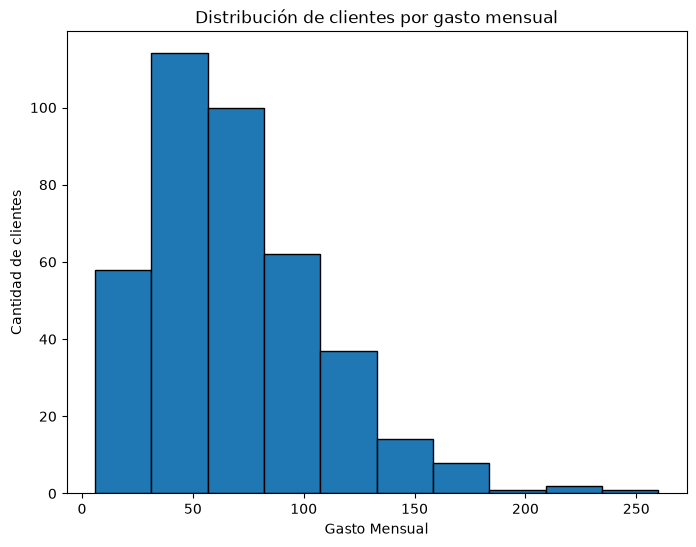

In [28]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8, 6))
plt.hist(df['gasto_mensual'], bins=10, edgecolor='black')
plt.xlabel('Gasto Mensual')
plt.ylabel('Cantidad de clientes')
plt.title('Distribución de clientes por gasto mensual')
plt.show()

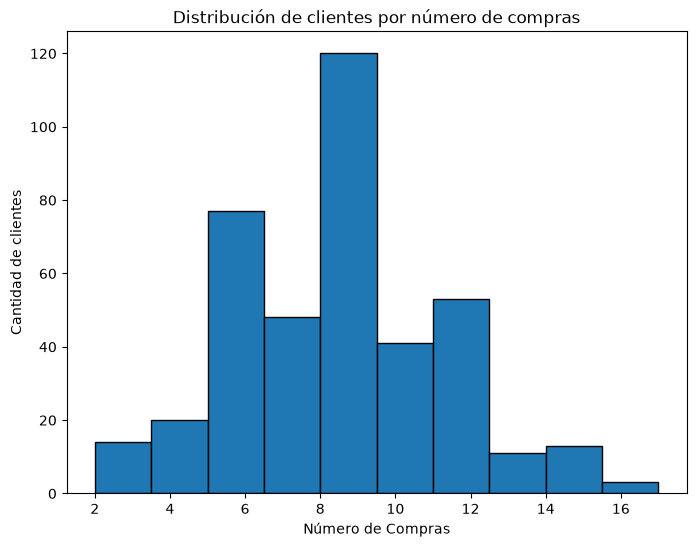

In [29]:
# TODO: histograma de num_compras
plt.figure(figsize=(8, 6))
plt.hist(df['num_compras'], bins=10, edgecolor='black')
plt.xlabel('Número de Compras')
plt.ylabel('Cantidad de clientes')
plt.title('Distribución de clientes por número de compras')
plt.show()

### Observaciones
- **edad:** La mayoría de los clientes tiene edades comprendidas entre 20 y 70 años, pero aparece un valor extremo cercano a 195 años, que probablemente sea un dato erróneo o atípico.
- **ingresos_anuales:** La distribución está concentrada entre 30.000 € y 50.000 €, con una ligera asimetría hacia la derecha debido a algunos clientes con ingresos elevados (hasta aproximadamente 83.000 €). 
- **gasto_mensual:** La mayor parte de los clientes gasta entre 30 € y 100 € al mes. La distribución está claramente sesgada a la derecha y existen algunos valores altos aislados (hasta unos 260 €).
- **num_compras:** La distribución está centrada alrededor de 8 compras, con la mayoría de los clientes realizando entre 6 y 10 compras. No se observan valores atípicos tan evidentes como en la variable edad.

## Parte 9 - Un mismo dataset, diferentes problemas
### Ejercicio 17 - Problema A
> ¿Realizará el cliente una compra el próximo mes?

Completa y justifica:
- Target: compra_proximo_mes
- ¿Existe \(y\)?: Sí, y = compra_proximo_mes
- Supervisado / no supervisado: Supervisado, porque conocemos la respuesta correcta para cada cliente (Sí o No).
- Clasificación / regresión / clustering: Clasificación, porque se quiere predecir una categoría.
- Binaria / multiclase: Binaria, porque solo hay dos posibles resultados.

**Justificación:** 
La variable objetivo es compra_proximo_mes, que indica si un cliente realizará una compra el próximo mes. Como el dataset incluye esa etiqueta para cada cliente, se trata de un problema de aprendizaje supervisado. Además, la respuesta posible es Sí o No, por lo que es un problema de clasificación binaria.

### Ejercicio 18 - Problema B
Supón una columna `gasto_proximo_mes` con cantidades monetarias.

> ¿Cuánto gastará el cliente el próximo mes?

1. ¿Cuál sería \(y\)? 
2. ¿Qué tipo de variable? 
3. ¿Supervisado? Sí, es un problema de aprendizaje supervisado, porque conocemos el valor objetivo (gasto_proximo_mes) para cada cliente durante el entrenamiento.
4. ¿Clasificación o regresión? Regresión
5. ¿Por qué? Porque se quiere predecir una cantidad numérica (cuánto dinero gastará el cliente el próximo mes), no una categoría como "Sí" o "No". Los problemas de regresión predicen valores continuos.

**Respuesta:** Escribe aquí.
1. gasto_proximo_mes
2. Es una variable numérica continua, ya que representa una cantidad de dinero (€) y puede tomar muchos valores diferentes.
3. Sí, es un problema de aprendizaje supervisado, porque conocemos el valor objetivo (gasto_proximo_mes) para cada cliente durante el entrenamiento.
4. Regresión.
5. Porque se quiere predecir una cantidad numérica (cuánto dinero gastará el cliente el próximo mes), no una categoría como "Sí" o "No". Los problemas de regresión predicen valores continuos.


### Ejercicio 19 - Problema C
> Descubrir grupos de clientes similares sin grupos definidos previamente.

1. ¿Existe etiqueta de grupo?
2. ¿Necesitamos \(y\)?
3. ¿Supervisado o no supervisado?
4. ¿Qué técnica usaríamos?
5. ¿Qué variables podrían describir los grupos?

**Respuesta:** Escribe aquí.
1. No. Los grupos de clientes no están definidos previamente en el dataset.
2. No. No existe una variable objetivo que queramos predecir.
3. Es un problema de aprendizaje no supervisado.
4. Clustering (agrupamiento de clientes), por ejemplo utilizando algoritmos como K-Means.
5. Edad, antigüedad, ingresos anuales, gasto mensual, número de compras, devoluciones, satisfacción y nivel de fidelidad.


## Parte 10 - Razonamiento
### Ejercicio 20 - ¿Una columna puede cambiar de papel?
¿Por qué una misma variable puede actuar como característica en un problema y como objetivo en otro?

**Respuesta:** Escribe aquí.

Sí. Una misma variable puede actuar como característica (X) en un problema y como variable objetivo (y) en otro, dependiendo de lo que se quiera predecir.

Por ejemplo:

- Si queremos predecir si un cliente realizará una compra el próximo mes, gasto_mensual sería una característica (X).
- Si queremos predecir cuánto gastará un cliente el próximo mes, entonces gasto_proximo_mes sería la variable objetivo (y), y otras variables como edad, ingresos o número de compras actuarían como características.

Conclusión: El papel de una columna no depende de la propia columna, sino del objetivo del análisis o del modelo que se quiere construir.

### Ejercicio 21 - ¿Qué está mal aquí?
Un compañero hace:

```python
X = df.drop(columns=["compra_proximo_mes"])
y = df["compra_proximo_mes"]
```

y afirma que todas las columnas de `X` ya son características adecuadas.

¿Estás de acuerdo? Identifica al menos dos cuestiones que revisarías.

**Respuesta:** Escribe aquí.

No estoy de acuerdo. Que se haya eliminado compra_proximo_mes no garantiza que todas las columnas restantes sean características adecuadas.

Dos aspectos que revisaría son:

1. La columna cliente_id

- Es un identificador único de cada cliente.
- No aporta información útil para predecir comportamientos.
- Debería eliminarse de X.

2. Los tipos de las variables categóricas

- Variables como dispositivo, zona o nivel_fidelidad son categóricas.
- No pueden utilizarse directamente en muchos modelos y suelen necesitar una transformación (por ejemplo, codificación u encoding).

Además, también revisaría:

- La existencia de valores ausentes en antiguedad_meses, ingresos_anuales y gasto_mensual.
- La presencia de valores atípicos, como la edad de 195 años detectada anteriormente.

Conclusión: Antes de afirmar que todas las columnas de X son adecuadas, hay que revisar identificadores, valores faltantes, tipos de datos y posibles valores anómalos.

## Parte 11 - Ficha técnica
### Ejercicio 22

```text
FICHA DEL DATASET
=================
Nombre: Clientes e-commerce
Número de muestras: 400
Número de columnas: 12
Unidad de observación: Cliente
Identificador: cliente_id
Target: compra_proximo_mes
Tipo de target: Categórica binaria (Sí/No)
Número de features candidatas: 10
Features numéricas: edad, antiguedad_meses, ingresos_anuales, gasto_mensual, num_compras, devoluciones.
Features categóricas nominales: dispositivo, zona.
Features ordinales: nivel_fidelidad, satisfaccion.
Datos etiquetados: Sí
Valores ausentes: antiguedad_meses: 5, ingresos_anuales: 4, gasto_mensual: 3. Total: 12 valores ausentes.
Problema principal: Predecir si un cliente realizará una compra el próximo mes.
Tipo de aprendizaje: Supervisado.
Tipo de tarea: Clasificación binaria
```

## Parte 12 - Conclusiones
### Ejercicio 23
Escribe entre **10 y 15 líneas** incluyendo: muestra, dimensiones, columnas vs. features, identificador, tipos de variables, target, \(X\), \(y\), etiquetado, ausentes, distribuciones, posible problema de calidad y tipo de problema de ML.

### Conclusiones

El dataset Clientes e-commerce contiene 400 muestras y 12 columnas, donde cada fila representa un cliente. La columna cliente_id actúa como identificador y no debe utilizarse como característica predictiva. Aunque existen 12 columnas, solo hay 10 features candidatas, ya que se excluyen cliente_id y la variable objetivo compra_proximo_mes.

El target es compra_proximo_mes, una variable categórica con valores Sí/No, por lo que el conjunto de datos está etiquetado y permite aplicar técnicas de aprendizaje supervisado. Las variables incluyen características numéricas (edad, ingresos_anuales, gasto_mensual, etc.), categóricas nominales (dispositivo, zona) y ordinales (nivel_fidelidad, satisfaccion).

Se detectaron 12 valores ausentes repartidos entre antiguedad_meses, ingresos_anuales y gasto_mensual, aunque representan un porcentaje bajo del total. En el análisis exploratorio también apareció un posible problema de calidad en la variable edad, con un valor máximo de 195 años, claramente sospechoso.

Las distribuciones muestran que la mayoría de clientes tienen edades entre 20 y 70 años, ingresos concentrados entre 30.000 € y 50.000 €, gasto mensual moderado y un número de compras centrado alrededor de 8. Además, el uso de móvil es claramente predominante frente a otros dispositivos.

En conjunto, el principal objetivo del dataset es predecir si un cliente realizará una compra el próximo mes, lo que corresponde a un problema de clasificación binaria supervisada.

# Ampliación opcional - El reto del analista
Mediante pandas, responde e interpreta:

1. ¿Qué nivel de fidelidad presenta mayor gasto mensual medio?
2. ¿El gasto histórico medio difiere entre quienes compran el mes siguiente y quienes no?
3. ¿Qué dispositivo tiene mayor número medio de compras?
4. ¿Cuál es la satisfacción media por nivel de fidelidad?
5. ¿Qué porcentaje de clientes de cada nivel compra el mes siguiente?

> Una asociación no demuestra causalidad.

In [ ]:
# TODO: ampliación opcional

# Antes de entregar
- Completa todos los `TODO`.
- Responde las preguntas en Markdown.
- Añade títulos y etiquetas a los gráficos.
- Ejecuta el notebook completo desde el principio y comprueba que no hay errores.
- Justifica tus decisiones.

**Nombre recomendado:** `Practica_04_Apellido_Nombre.ipynb`